In [1]:
import gymnasium as gym
env = gym.make(
    'FrozenLake-v1',
    desc=None,
    map_name="8x8",
    is_slippery=True,
    success_rate=1.0/3.0,
    reward_schedule=(1, 0, 0)
)

state, info = env.reset()

In [2]:
print(env.observation_space)
print(env.action_space)

Discrete(64)
Discrete(4)


# Problem 1
## The goal

The goal of the environment is to travel from the starting tile from the to top left to the goal at the bottom right without falling into the a hole in the map

## State/observation space

There are 64 states, numbered 0-63. Each state represents a tile. Its number is $s = 8 \times row + column$, using zero-based indexing. No state discretization is needed because FrozenLake already provides discrete states.

## Action Spaces

There are 4 possible actions. 0 = left, 1 = down, 2 = right, 3 = up.

## Transition Dynamics

We are using is_slippery = True with the success rate as 1/3. This means that the agent wants to move a direction, the chance that it gets the to move in the right direction is 1/3. Otherwise, it will move in either direction perpendicular to the move with equal probability in both directions. 

## Rewards

Reaching the goal gives +1 while falling into the hole or moving onto a safe tile gives 0. 

## Termination

Reaching the goal or falling into the hole ends the episode. Reaching the step limit causes truncation instead. 

## Settings 

Using 8x8 grid with slippery movement. 

## Part B: Implement Q-learning

Define the Q-learning function below. It initializes the Q-table, selects actions with epsilon-greedy exploration, handles terminal states, and updates Q-values. Training starts when Part C calls this function.

In [3]:
import numpy as np

def train_q_learning(env, alpha, gamma, epsilon_start, epsilon_decay,
                     epsilon_min, episodes):
    # Start each training run with a fresh Q-table, epsilon, and reward history.
    Q = np.zeros((64, 4))
    epsilon = epsilon_start
    episode_rewards = []

    for episode in range(episodes):
        state, info = env.reset()
        terminated = False
        truncated = False
        total_reward = 0

        while not (terminated or truncated):
            # Choose an action: explore or exploit
            if np.random.random() < epsilon:
                action = env.action_space.sample()
            else:
                best_actions = np.flatnonzero(
                    Q[state] == np.max(Q[state])
                )
                action = np.random.choice(best_actions)

            # Perform the action
            next_state, reward, terminated, truncated, info = env.step(action)

            # Add this step's reward to the episode total.
            total_reward += reward

            # Calculate the learning target
            if terminated:
                target = reward
            else:
                target = reward + gamma * np.max(Q[next_state])

            # Update the estimate for the action we just took
            Q[state, action] += alpha * (target - Q[state, action])

            # Move to the actual next state
            state = next_state
        # Record the episode reward and reduce exploration for the next episode.
        episode_rewards.append(total_reward)
        epsilon = max(epsilon_min, epsilon * epsilon_decay)

    # Check that every episode was recorded and epsilon stayed within its limits.
    assert len(episode_rewards) == episodes
    assert epsilon_min <= epsilon <= epsilon_start

    return Q, episode_rewards, epsilon


## Part C: Baseline training

Choose the baseline settings, call the Part B function to train the agent, then display the training results and reward plot.

In [4]:
#setting up the initial variables for Q value iteration

alpha = 0.1
gamma = 0.99
# Configure exploration and its decay after each episode.
epsilon_start = 1.0
epsilon_decay = 0.9995
epsilon_min = 0.05
epsilon = epsilon_start
episodes = 20000

In [5]:
# Train the baseline using the Q-learning implementation from Part B.
Q, episode_rewards, epsilon = train_q_learning(
    env, alpha, gamma, epsilon_start, epsilon_decay, epsilon_min, episodes
)

# Keep independent copies of this trained baseline for later comparisons.
baseline_Q = Q.copy()
baseline_episode_rewards = episode_rewards.copy()


In [6]:
print("Nonzero Q-values:", np.count_nonzero(Q))
print("Highest Q-value:", np.max(Q))
print("Starting tile Q-values:", Q[0])

# These rewards come from training episodes, which include exploration.
print("Training performance - final epsilon:", epsilon)
print("Training performance - average reward over the last 1000 episodes:",
      np.mean(episode_rewards[-1000:]))


Nonzero Q-values: 201
Highest Q-value: 0.926561337526617
Starting tile Q-values: [0.37108304 0.37172576 0.39176513 0.37841778]
Training performance - final epsilon: 0.05
Training performance - average reward over the last 1000 episodes: 0.398


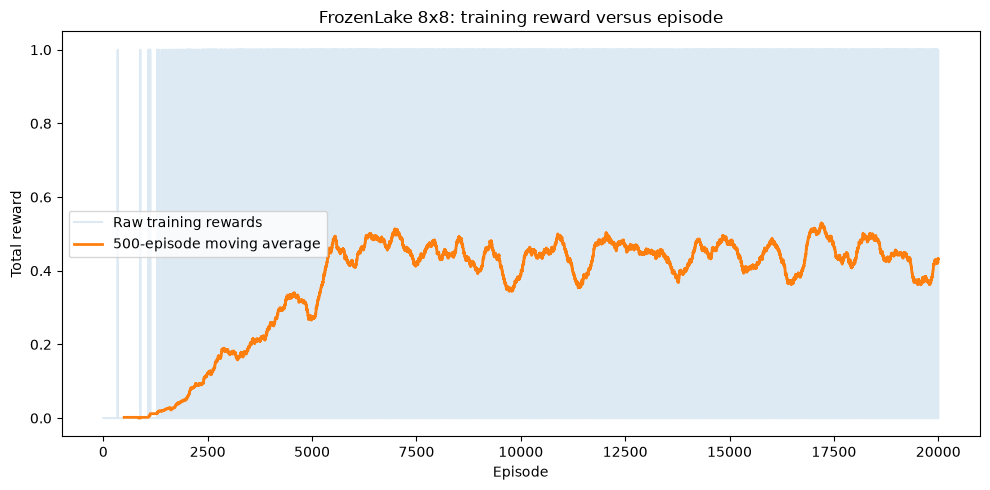

In [7]:
import matplotlib.pyplot as plt

# Average each group of 500 consecutive training episode rewards.
window = 500
moving_average = np.convolve(
    episode_rewards, np.ones(window) / window, mode="valid"
)
episode_numbers = np.arange(1, len(episode_rewards) + 1)

# Align each average with the last episode in its 500-episode window.
plt.figure(figsize=(10, 5))
plt.plot(episode_numbers, episode_rewards, alpha=0.15,
         label="Raw training rewards")
plt.plot(episode_numbers[window - 1:], moving_average,
         label="500-episode moving average", linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("FrozenLake 8x8: training reward versus episode")
plt.legend()
plt.tight_layout()
plt.show()


## Part D: Learning-rate experiment

Compare learning rates $\alpha = 0.1, 0.5, 0.9$. Keep the environment, discount factor, exploration schedule, and number of episodes the same as Part C. Run Parts B and C first so the training function and baseline results are available.

In [8]:
# Change only the learning rate for this experiment.
learning_rates = [0.1, 0.5, 0.9]
learning_rate_results = {}

for learning_rate in learning_rates:
    if learning_rate == alpha:
        # Reuse Part C's baseline instead of training the same setting again.
        trained_Q = baseline_Q.copy()
        training_rewards = baseline_episode_rewards.copy()
    else:
        # Part B's function starts each new run with a fresh Q-table and epsilon.
        trained_Q, training_rewards, final_epsilon = train_q_learning(
            env, learning_rate, gamma, epsilon_start, epsilon_decay,
            epsilon_min, episodes
        )

    # Keep each model and its rewards for comparison without replacing the baseline.
    learning_rate_results[learning_rate] = {
        "Q": trained_Q,
        "rewards": training_rewards
    }

    # Check that each run completed and produced valid Q-values.
    assert len(training_rewards) == episodes
    assert np.isfinite(trained_Q).all()
    print(f"Finished alpha = {learning_rate}: {len(training_rewards)} training episodes")


Finished alpha = 0.1: 20000 training episodes


Finished alpha = 0.5: 20000 training episodes


Finished alpha = 0.9: 20000 training episodes


Training performance (exploration is still enabled):
Alpha | First 5,000 mean reward | Last 1,000 mean reward
0.1   | 0.144                   | 0.398
0.5   | 0.089                   | 0.278
0.9   | 0.028                   | 0.124


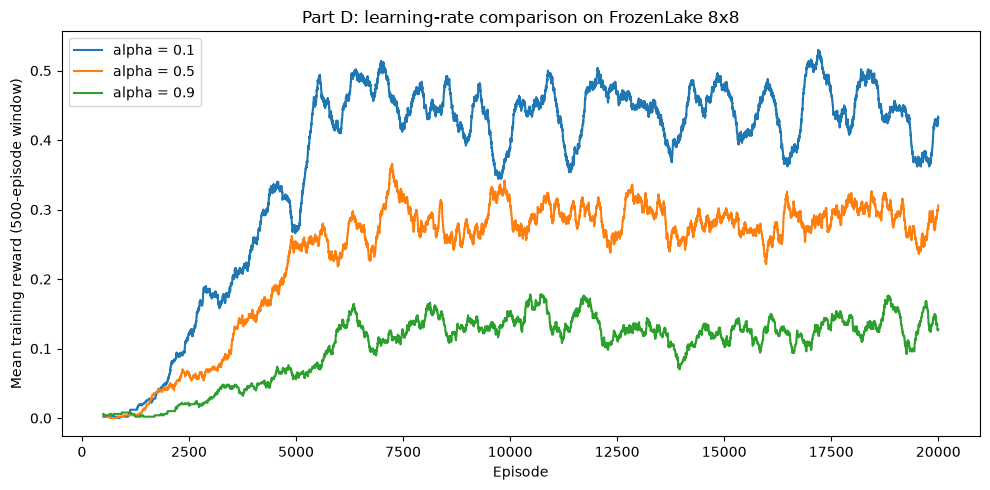

In [9]:
# Use the same 500-episode moving average for all three learning rates.
comparison_window = 500
plt.figure(figsize=(10, 5))

print("Training performance (exploration is still enabled):")
print("Alpha | First 5,000 mean reward | Last 1,000 mean reward")

for learning_rate in learning_rates:
    training_rewards = learning_rate_results[learning_rate]["rewards"]
    average_rewards = np.convolve(
        training_rewards,
        np.ones(comparison_window) / comparison_window,
        mode="valid"
    )

    # Each average ends at the episode number shown on the x-axis.
    comparison_episodes = np.arange(comparison_window, len(training_rewards) + 1)
    plt.plot(comparison_episodes, average_rewards, label=f"alpha = {learning_rate}")

    # Early rewards help compare learning speed; late rewards show final performance.
    early_reward = np.mean(training_rewards[:5000])
    final_reward = np.mean(training_rewards[-1000:])
    print(f"{learning_rate:.1f}   | {early_reward:.3f}                   | {final_reward:.3f}")

plt.xlabel("Episode")
plt.ylabel("Mean training reward (500-episode window)")
plt.title("Part D: learning-rate comparison on FrozenLake 8x8")
plt.legend()
plt.tight_layout()
plt.show()


### Part D: Observations from this run

Learning speed: $\alpha = 0.1$ improved earlier and had the highest mean reward over the first 5,000 episodes (0.144). The means for $\alpha = 0.5$ and $\alpha = 0.9$ were 0.089 and 0.028. A larger learning rate did not produce faster learning in this run.

Stability: All three moving-average curves fluctuated. After the initial learning period, $\alpha = 0.1$ stayed above the other curves, although it still had noticeable rises and drops. The lower curves also fluctuated, so a flatter curve alone does not mean a better policy.

Final training performance: The mean rewards over the last 1,000 episodes were 0.398, 0.278, and 0.124 for $\alpha = 0.1, 0.5, 0.9$, respectively. Because an episode earns 1 only on success, these correspond to training success rates of 39.8%, 27.8%, and 12.4%. The baseline learning rate of 0.1 performed best in this comparison. A smaller learning rate gives each new sample less weight, which may help when slippery movement produces variable outcomes.

These are single-run training results with exploration enabled, not Part G evaluation results. Rerunning can change the numbers and curves; update these observations if you rerun the experiment.

## Part E: Discount-factor experiment

Compare discount factors $\gamma = 0.50, 0.90, 0.99$. Keep the environment, learning rate, exploration schedule, and number of episodes the same as Part C. Run the environment setup, Part B, and Part C's settings cell first. Each discount factor gets a fresh training run, including $\gamma = 0.99$.


In [4]:
# Change only the discount factor for this experiment.
discount_factors = [0.50, 0.90, 0.99]
discount_factor_results = {}

for discount_factor in discount_factors:
    # Start each comparison with a fresh Q-table and exploration schedule.
    trained_Q, training_rewards, final_epsilon = train_q_learning(
        env, alpha, discount_factor, epsilon_start, epsilon_decay,
        epsilon_min, episodes
    )

    # Keep the results without replacing Part C's saved baseline.
    discount_factor_results[discount_factor] = {
        "Q": trained_Q,
        "rewards": training_rewards
    }

    # Check that each run completed and produced valid Q-values.
    assert len(training_rewards) == episodes
    assert np.isfinite(trained_Q).all()
    print(f"Finished gamma = {discount_factor:.2f}: {len(training_rewards)} training episodes")


Finished gamma = 0.50: 20000 training episodes


Finished gamma = 0.90: 20000 training episodes


Finished gamma = 0.99: 20000 training episodes


Matplotlib is building the font cache; this may take a moment.


Training performance (exploration is still enabled):
Gamma | First 5,000 mean reward | Last 1,000 mean reward
0.50  | 0.020                   | 0.037
0.90  | 0.108                   | 0.299
0.99  | 0.149                   | 0.471


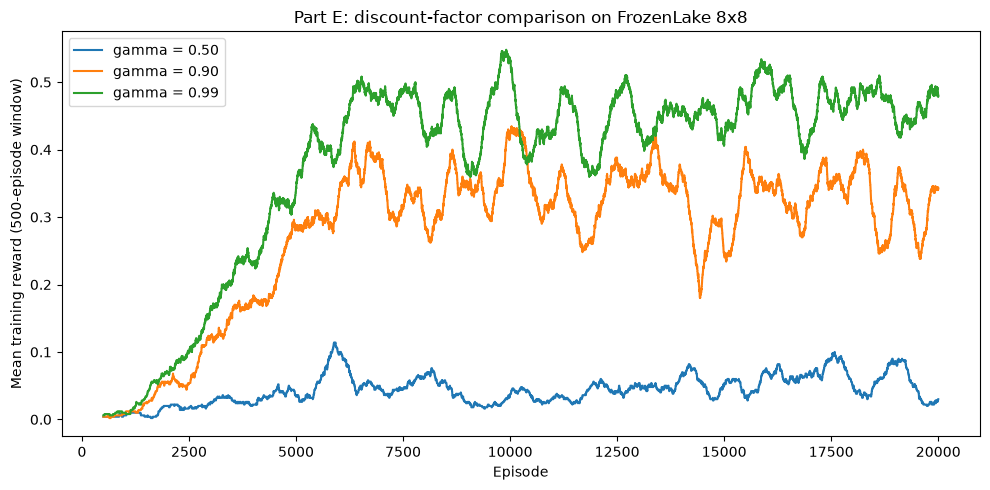

In [5]:
import matplotlib.pyplot as plt

# Use the same 500-episode moving average as Part D.
comparison_window = 500
plt.figure(figsize=(10, 5))

print("Training performance (exploration is still enabled):")
print("Gamma | First 5,000 mean reward | Last 1,000 mean reward")

for discount_factor in discount_factors:
    training_rewards = discount_factor_results[discount_factor]["rewards"]
    average_rewards = np.convolve(
        training_rewards,
        np.ones(comparison_window) / comparison_window,
        mode="valid"
    )

    # Each average ends at the episode number shown on the x-axis.
    comparison_episodes = np.arange(comparison_window, len(training_rewards) + 1)
    plt.plot(comparison_episodes, average_rewards,
             label=f"gamma = {discount_factor:.2f}")

    # Compare early learning with performance near the end of training.
    early_reward = np.mean(training_rewards[:5000])
    final_reward = np.mean(training_rewards[-1000:])
    print(f"{discount_factor:.2f}  | {early_reward:.3f}                   | {final_reward:.3f}")

plt.xlabel("Episode")
plt.ylabel("Mean training reward (500-episode window)")
plt.title("Part E: discount-factor comparison on FrozenLake 8x8")
plt.legend()
plt.tight_layout()
plt.show()


### Part E: Observations from this run

Learning speed: $\gamma = 0.99$ had the highest mean reward over the first 5,000 episodes (0.149), followed by $\gamma = 0.90$ (0.108) and $\gamma = 0.50$ (0.020). The higher discount factors improved earlier in this run.

Stability: All three moving-average curves fluctuated. After the initial learning period, $\gamma = 0.99$ generally maintained higher mean rewards than the other settings. The curve for $\gamma = 0.50$ stayed low, so its smaller fluctuations did not indicate a better policy.

Final training performance: The mean rewards over the last 1,000 episodes were 0.037, 0.299, and 0.471 for $\gamma = 0.50, 0.90, 0.99$, respectively. Since an episode earns 1 only when the agent reaches the goal, these correspond to training success rates of 3.7%, 29.9%, and 47.1%. The discount factor of 0.99 performed best in this comparison.

Immediate versus future rewards: A lower discount factor gives less weight to rewards that are many steps away. FrozenLake gives no positive reward until the goal, so $\gamma = 0.50$ greatly reduces the value of that future reward at earlier states. A value closer to 1 preserves more of its value, which can help the agent learn actions that lead to the distant goal. The stronger results for $\gamma = 0.99$ are consistent with this explanation.

These are single-run training results with exploration enabled, not Part G evaluation results. The $\gamma = 0.99$ setting was trained again rather than reusing Part C's baseline, so its results differ even though the settings match. Rerunning can change the numbers and curves; update these observations if you rerun the experiment.


## Part F: Exploration-decay experiment

Compare exploration-decay factors $0.99$, $0.9995$, and $0.9999$. Keep the environment, learning rate, discount factor, starting epsilon, minimum epsilon, and number of episodes the same as Part C. Run the environment setup, Part B, and Part C's settings cell first. Each setting gets a fresh training run, including the baseline decay factor of $0.9995$.

After each episode, epsilon is multiplied by the decay factor until it reaches the minimum of $0.05$. A smaller factor reduces exploration faster, while a factor closer to 1 keeps exploration active longer.


In [4]:
# Change only the exploration-decay factor for this experiment.
epsilon_decay_rates = [0.99, 0.9995, 0.9999]
epsilon_decay_results = {}

for decay_rate in epsilon_decay_rates:
    # Start each comparison with a fresh Q-table and exploration schedule.
    trained_Q, training_rewards, final_epsilon = train_q_learning(
        env, alpha, gamma, epsilon_start, decay_rate,
        epsilon_min, episodes
    )

    # Keep each model and its rewards without replacing the baseline.
    epsilon_decay_results[decay_rate] = {
        "Q": trained_Q,
        "rewards": training_rewards,
        "final_epsilon": final_epsilon
    }

    # Check that training completed and the exploration schedule was applied.
    assert len(training_rewards) == episodes
    assert np.isfinite(trained_Q).all()
    assert np.isclose(final_epsilon,
                      max(epsilon_min, epsilon_start * decay_rate ** episodes))
    print(f"Finished epsilon decay = {decay_rate}: {len(training_rewards)} training episodes")


Finished epsilon decay = 0.99: 20000 training episodes


Finished epsilon decay = 0.9995: 20000 training episodes


Finished epsilon decay = 0.9999: 20000 training episodes


Training performance (exploration is still enabled):
Epsilon decay | First 5,000 mean reward | Last 1,000 mean reward | Final epsilon
0.99          | 0.078                   | 0.459                  | 0.050
0.9995        | 0.133                   | 0.416                  | 0.050
0.9999        | 0.009                   | 0.313                  | 0.135


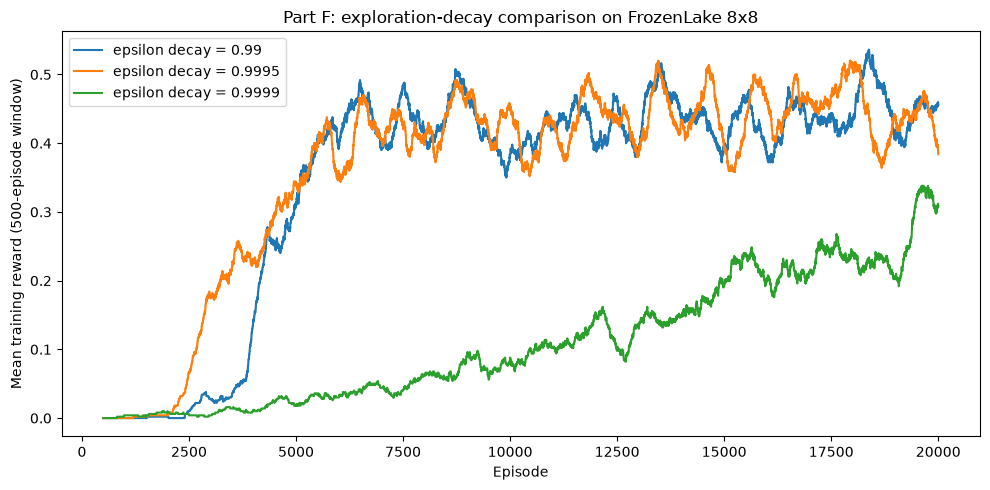

In [5]:
import matplotlib.pyplot as plt

# Use the same 500-episode moving average as Parts D and E.
comparison_window = 500
plt.figure(figsize=(10, 5))

print("Training performance (exploration is still enabled):")
print("Epsilon decay | First 5,000 mean reward | Last 1,000 mean reward | Final epsilon")

for decay_rate in epsilon_decay_rates:
    training_rewards = epsilon_decay_results[decay_rate]["rewards"]
    average_rewards = np.convolve(
        training_rewards,
        np.ones(comparison_window) / comparison_window,
        mode="valid"
    )

    # Each average ends at the episode number shown on the x-axis.
    comparison_episodes = np.arange(comparison_window, len(training_rewards) + 1)
    plt.plot(comparison_episodes, average_rewards,
             label=f"epsilon decay = {decay_rate}")

    # Final epsilon helps explain how much exploration remains in each run.
    early_reward = np.mean(training_rewards[:5000])
    final_reward = np.mean(training_rewards[-1000:])
    final_epsilon = epsilon_decay_results[decay_rate]["final_epsilon"]
    print(f"{decay_rate:<13} | {early_reward:.3f}                   | "
          f"{final_reward:.3f}                  | {final_epsilon:.3f}")

plt.xlabel("Episode")
plt.ylabel("Mean training reward (500-episode window)")
plt.title("Part F: exploration-decay comparison on FrozenLake 8x8")
plt.legend()
plt.tight_layout()
plt.show()


### Part F: Observations from this run

Learning speed: The baseline decay factor of $0.9995$ improved earlier and had the highest mean reward over the first 5,000 episodes (0.133). The means for decay factors $0.99$ and $0.9999$ were 0.078 and 0.009. Keeping exploration high for longer did not produce faster learning in this run.

Stability: The curves for $0.99$ and $0.9995$ both fluctuated and often reached similar reward levels later in training. The curve for $0.9999$ improved more gradually but remained below the other two for most of training. Its smaller fluctuations alone do not show a better policy.

Final training performance: The mean rewards over the last 1,000 episodes were 0.459, 0.416, and 0.313 for decay factors $0.99$, $0.9995$, and $0.9999$, respectively. Since an episode earns 1 only on success, these correspond to training success rates of 45.9%, 41.6%, and 31.3%. The fastest decay factor, $0.99$, had the highest final training performance in this comparison, even though $0.9995$ improved earlier.

Effect of exploration decay: The factor $0.99$ reaches the minimum epsilon of $0.05$ after 299 episodes, while $0.9995$ reaches it after 5,990 episodes. A faster decay allows the agent to use its current preferred actions sooner, but can reduce its chance to discover better actions. The factor $0.9999$ still has an epsilon of about $0.135$ after 20,000 episodes, so it continues choosing random actions about 13.5% of the time, compared with 5% for the other settings. This longer exploration period can lower training rewards even as the agent learns.

These are single-run training results with exploration enabled, not Part G evaluation results. The baseline decay factor of $0.9995$ was trained again, so its results differ from Part C despite using the same settings. Exploration-free evaluation is needed to compare the learned policies. Rerunning can change the numbers and curves; update these observations if you rerun the experiment.


## Part G: Evaluate the best agent

Choose $\alpha = 0.1$ from Part D, $\gamma = 0.99$ from Part E, and exploration decay $0.99$ from Part F. Each had the highest mean reward over the last 1,000 training episodes in its experiment. Combine these settings for the selected agent. Keep the other settings from Part C: starting epsilon $1.0$, minimum epsilon $0.05$, and 20,000 training episodes. This selection uses training results only, before looking at evaluation results. Update the selection if rerunning Parts D through F changes their conclusions.

Run the environment setup, Part B, and Part C's settings cell first. Train the selected configuration and a fresh baseline with the same training seed. This baseline uses Part C's configuration, but is trained again for this comparison; Part C's saved Q-table is not replaced.

Evaluate each policy over 100 episodes with $\epsilon = 0$. Always choose an action with the highest Q-value, break ties with the first maximum, and do not update the Q-table. Use the same episode seeds for both policies so the comparison is repeatable. Report mean reward, success rate, and mean steps on successful episodes. Slippery movement remains enabled during evaluation.


In [4]:
# Select settings from the completed experiments before running evaluation.
best_alpha = 0.1
best_gamma = 0.99
best_epsilon_decay = 0.99
training_seed = 42
final_training_results = {}

for name, learning_rate, discount_factor, decay_rate in [
    ("Baseline", alpha, gamma, epsilon_decay),
    ("Selected agent", best_alpha, best_gamma, best_epsilon_decay)
]:
    # Reset all training randomness so both configurations use the same seed.
    np.random.seed(training_seed)
    env.reset(seed=training_seed)
    env.action_space.seed(training_seed)
    trained_Q, training_rewards, final_epsilon = train_q_learning(
        env, learning_rate, discount_factor, epsilon_start, decay_rate,
        epsilon_min, episodes
    )
    final_training_results[name] = {
        "Q": trained_Q,
        "rewards": training_rewards
    }

    assert len(training_rewards) == episodes
    assert np.isfinite(trained_Q).all()
    print(f"{name}: alpha = {learning_rate}, gamma = {discount_factor}, "
          f"epsilon decay = {decay_rate}, {len(training_rewards)} training episodes")


Baseline: alpha = 0.1, gamma = 0.99, epsilon decay = 0.9995, 20000 training episodes


Selected agent: alpha = 0.1, gamma = 0.99, epsilon decay = 0.99, 20000 training episodes


In [5]:
def evaluate_policy(env, trained_Q, episode_seeds):
    rewards = []
    episode_steps = []

    for seed in episode_seeds:
        state, info = env.reset(seed=seed)
        terminated = False
        truncated = False
        total_reward = 0
        steps = 0

        while not (terminated or truncated):
            # Greedy actions disable exploration; evaluation never updates Q.
            action = int(np.argmax(trained_Q[state]))
            state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            steps += 1

        rewards.append(total_reward)
        episode_steps.append(steps)

    return rewards, episode_steps


evaluation_episodes = 100
# Separate evaluation seeds from the training seed and reuse them for both policies.
evaluation_seeds = range(10000, 10000 + evaluation_episodes)
evaluation_results = {}
assert evaluation_episodes >= 30

print("Evaluation performance (epsilon = 0; no Q-value updates):")
print("Agent          | Mean reward | Success rate | Mean steps on success")

for name, training_result in final_training_results.items():
    policy_Q = training_result["Q"]
    Q_before_evaluation = policy_Q.copy()
    rewards, steps = evaluate_policy(env, policy_Q, evaluation_seeds)
    successful_steps = [length for reward, length in zip(rewards, steps)
                        if reward > 0]
    mean_reward = np.mean(rewards)
    success_rate = len(successful_steps) / evaluation_episodes
    # No successful episodes means steps to the goal cannot be measured.
    mean_success_steps = np.mean(successful_steps) if successful_steps else np.nan
    evaluation_results[name] = {
        "rewards": rewards,
        "steps": steps,
        "mean_reward": mean_reward,
        "success_rate": success_rate,
        "mean_success_steps": mean_success_steps
    }

    # Check episode bookkeeping and confirm evaluation did not train the agent.
    assert len(rewards) == len(steps) == evaluation_episodes
    assert np.array_equal(policy_Q, Q_before_evaluation)
    assert np.isclose(mean_reward, success_rate)
    print(f"{name:<14} | {mean_reward:.3f}       | {success_rate:.1%}        | "
          f"{mean_success_steps:.1f}")

print("Steps on success is NaN if the agent never reached the goal.")


Evaluation performance (epsilon = 0; no Q-value updates):
Agent          | Mean reward | Success rate | Mean steps on success
Baseline       | 0.370       | 37.0%        | 63.2
Selected agent | 0.230       | 23.0%        | 69.3
Steps on success is NaN if the agent never reached the goal.


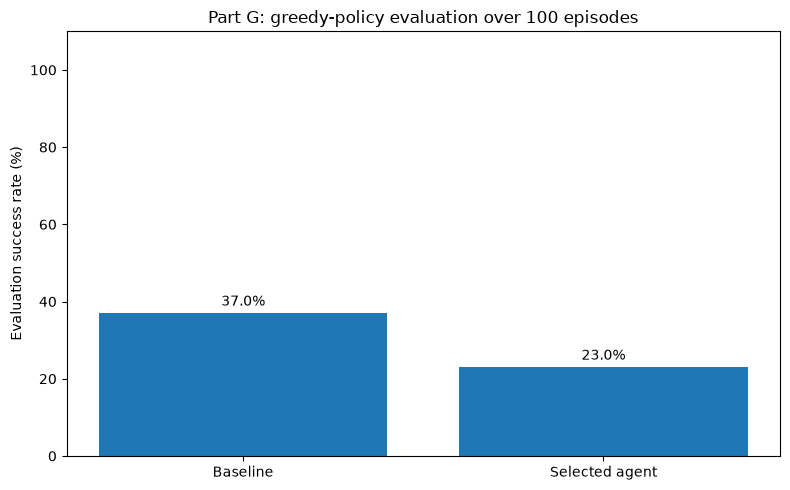

In [6]:
import matplotlib.pyplot as plt

agent_names = list(evaluation_results)
success_rates = [evaluation_results[name]["success_rate"] * 100
                 for name in agent_names]

plt.figure(figsize=(8, 5))
bars = plt.bar(agent_names, success_rates)
plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.ylim(0, 110)
plt.ylabel("Evaluation success rate (%)")
plt.title(f"Part G: greedy-policy evaluation over {evaluation_episodes} episodes")
plt.tight_layout()
plt.show()


### Part G: Observations from this run

Configuration selection: The selected agent uses $\alpha = 0.1$, $\gamma = 0.99$, and exploration decay $0.99$, based on the highest mean rewards over the last 1,000 episodes in Parts D, E, and F, respectively. It uses 20,000 training episodes, starting epsilon $1.0$, and minimum epsilon $0.05$. The baseline uses the same settings except for exploration decay $0.9995$. Both agents were trained again with seed 42 for this comparison.

Evaluation results: With exploration disabled, the baseline reached the goal in 37 of 100 episodes, giving a mean reward of 0.370 and a success rate of 37.0%. The selected agent reached the goal in 23 of 100 episodes, giving a mean reward of 0.230 and a success rate of 23.0%. The baseline's success rate was 14 percentage points higher. Mean reward equals success rate here because the only positive episode reward is 1 for reaching the goal.

Steps to completion: On successful episodes, the baseline took an average of 63.2 steps, compared with 69.3 steps for the selected agent. Failed episodes are excluded from this metric so falling into a hole quickly is not counted as reaching the goal efficiently. The averages describe each policy's successful episodes, which may be different episodes.

Training versus evaluation: In these fresh training runs, the last-1,000 mean rewards were 0.424 for the baseline and 0.437 for the selected agent. The slightly higher training reward for the selected agent did not lead to higher evaluation performance. Training still includes random exploratory actions; evaluation always follows the greedy policy. Different training histories and slippery transitions can also affect the outcome.

Conclusion from this run: The baseline performed better in this evaluation. Selecting decay $0.99$ from the training experiment did not demonstrate an improvement over the baseline when exploration was disabled. These results come from one training seed and 100 evaluation episodes per policy, so they do not establish that either configuration is always better. Both policies used the same evaluation seeds, and the checks confirmed their Q-tables did not change during evaluation. Rerunning the training or changing the evaluation seeds can change the results; update these observations if you rerun the experiment.


## Part H: Added action noise

FrozenLake is already stochastic because slippery movement is enabled. Add a separate source of uncertainty: with probability $p$, replace the intended action with one of the other three valid actions, chosen uniformly. The usual slippery movement then applies to that action. Test $p = 0$, $0.10$, and $0.25$. Here $p = 0$ means no added action noise; slippery movement remains enabled.

Keep Part C's training settings fixed: $\alpha = 0.1$, $\gamma = 0.99$, exploration decay $0.9995$, starting epsilon $1.0$, minimum epsilon $0.05$, and 20,000 training episodes. Train a fresh Q-table at each noise level using training seed 42. This uses the baseline configuration that performed better in Part G. Run the earlier sections first so Part B's training function and Part G's evaluation function are available.

Evaluate each trained policy for 100 episodes under its own training noise level, with exploration disabled and no Q-value updates. Also evaluate the original $p = 0$ policy under all three noise levels without retraining it. Use the same evaluation seeds for each comparison. Compare training curves, final training rewards, and evaluation rewards to see how added noise affects learning and the original policy's performance.


In [5]:
class ActionNoiseWrapper(gym.ActionWrapper):
    def __init__(self, env, noise_probability):
        if not 0 <= noise_probability <= 1:
            raise ValueError("Noise probability must be between 0 and 1.")
        super().__init__(env)
        self.noise_probability = noise_probability
        self.noise_rng = np.random.default_rng()

    def reset(self, *, seed=None, options=None):
        # Use a separate random stream so noise does not consume slippery-movement draws.
        if seed is not None:
            self.noise_rng = np.random.default_rng(seed + 1)
        return super().reset(seed=seed, options=options)

    def action(self, action):
        if self.noise_probability > 0 and self.noise_rng.random() < self.noise_probability:
            # A replaced action must differ from the intended action.
            other_actions = [a for a in range(self.action_space.n) if a != action]
            return int(self.noise_rng.choice(other_actions))
        return action


# Check the two extremes: no replacements and a replacement on every step.
for test_probability in [0.0, 1.0]:
    with ActionNoiseWrapper(gym.make(env.spec), test_probability) as test_env:
        test_env.reset(seed=42)
        test_actions = [test_env.action(0) for _ in range(100)]
        assert all(test_env.action_space.contains(a) for a in test_actions)
        if test_probability == 0.0:
            assert test_actions == [0] * 100
        else:
            assert all(a != 0 for a in test_actions)
print("Action-noise checks passed.")


Action-noise checks passed.


In [6]:
noise_levels = [0.0, 0.10, 0.25]
noise_training_results = {}
noise_training_seed = 42

for noise_probability in noise_levels:
    # Copy the original environment settings, including its slippery movement and step limit.
    with ActionNoiseWrapper(gym.make(env.spec), noise_probability) as noisy_env:
        np.random.seed(noise_training_seed)
        noisy_env.reset(seed=noise_training_seed)
        noisy_env.action_space.seed(noise_training_seed)
        trained_Q, training_rewards, final_epsilon = train_q_learning(
            noisy_env, alpha, gamma, epsilon_start, epsilon_decay,
            epsilon_min, episodes
        )

    noise_training_results[noise_probability] = {
        "Q": trained_Q,
        "rewards": training_rewards
    }
    assert len(training_rewards) == episodes
    assert np.isfinite(trained_Q).all()
    print(f"Finished p = {noise_probability:.2f}: {len(training_rewards)} training episodes")


Finished p = 0.00: 20000 training episodes


Finished p = 0.10: 20000 training episodes


Finished p = 0.25: 20000 training episodes


In [7]:
noise_evaluation_episodes = 100
noise_evaluation_seeds = range(10000, 10000 + noise_evaluation_episodes)
noise_evaluation_results = {}
original_noise_Q = noise_training_results[0.0]["Q"]
original_noise_Q_before = original_noise_Q.copy()
assert noise_evaluation_episodes >= 30

print("Evaluation performance (epsilon = 0; added environmental noise remains active):")
print("p    | Trained mean reward | Trained success | Original mean reward | Original success")

for noise_probability in noise_levels:
    policy_Q = noise_training_results[noise_probability]["Q"]
    Q_before_evaluation = policy_Q.copy()
    with ActionNoiseWrapper(gym.make(env.spec), noise_probability) as noisy_env:
        # Compare both policies under the same noise level and episode seeds.
        trained_rewards, trained_steps = evaluate_policy(
            noisy_env, policy_Q, noise_evaluation_seeds
        )
        original_rewards, original_steps = evaluate_policy(
            noisy_env, original_noise_Q, noise_evaluation_seeds
        )

    trained_mean_reward = np.mean(trained_rewards)
    original_mean_reward = np.mean(original_rewards)
    trained_success = np.mean(np.array(trained_rewards) > 0)
    original_success = np.mean(np.array(original_rewards) > 0)
    noise_evaluation_results[noise_probability] = {
        "trained_rewards": trained_rewards,
        "trained_steps": trained_steps,
        "original_rewards": original_rewards,
        "original_steps": original_steps,
        "trained_mean_reward": trained_mean_reward,
        "original_mean_reward": original_mean_reward,
        "trained_success": trained_success,
        "original_success": original_success
    }

    assert len(trained_rewards) == len(trained_steps) == noise_evaluation_episodes
    assert len(original_rewards) == len(original_steps) == noise_evaluation_episodes
    assert np.array_equal(policy_Q, Q_before_evaluation)
    assert np.array_equal(original_noise_Q, original_noise_Q_before)
    assert np.isclose(trained_mean_reward, trained_success)
    assert np.isclose(original_mean_reward, original_success)
    print(f"{noise_probability:.2f} | {trained_mean_reward:.3f}               | "
          f"{trained_success:.1%}           | {original_mean_reward:.3f}                | "
          f"{original_success:.1%}")

# At p = 0, both evaluations must use the same policy under identical conditions.
assert noise_evaluation_results[0.0]["trained_rewards"] == noise_evaluation_results[0.0]["original_rewards"]
assert noise_evaluation_results[0.0]["trained_steps"] == noise_evaluation_results[0.0]["original_steps"]


Evaluation performance (epsilon = 0; added environmental noise remains active):
p    | Trained mean reward | Trained success | Original mean reward | Original success
0.00 | 0.370               | 37.0%           | 0.370                | 37.0%
0.10 | 0.210               | 21.0%           | 0.140                | 14.0%
0.25 | 0.080               | 8.0%           | 0.070                | 7.0%


Training performance (exploration is still enabled):
p    | First 5,000 mean reward | Last 1,000 mean reward
0.00 | 0.131                   | 0.424
0.10 | 0.021                   | 0.220
0.25 | 0.028                   | 0.069


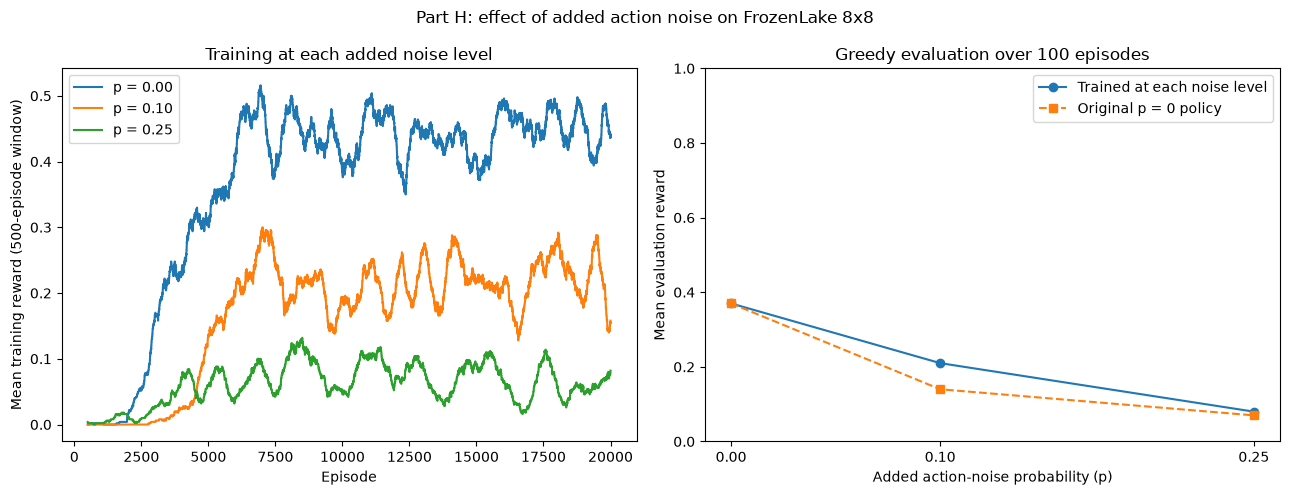

In [8]:
import matplotlib.pyplot as plt

noise_comparison_window = 500
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

print("Training performance (exploration is still enabled):")
print("p    | First 5,000 mean reward | Last 1,000 mean reward")

for noise_probability in noise_levels:
    training_rewards = noise_training_results[noise_probability]["rewards"]
    average_rewards = np.convolve(
        training_rewards,
        np.ones(noise_comparison_window) / noise_comparison_window,
        mode="valid"
    )
    comparison_episodes = np.arange(noise_comparison_window, len(training_rewards) + 1)
    axes[0].plot(comparison_episodes, average_rewards, label=f"p = {noise_probability:.2f}")
    print(f"{noise_probability:.2f} | {np.mean(training_rewards[:5000]):.3f}                   | "
          f"{np.mean(training_rewards[-1000:]):.3f}")

axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Mean training reward (500-episode window)")
axes[0].set_title("Training at each added noise level")
axes[0].legend()

matched_rewards = [noise_evaluation_results[p]["trained_mean_reward"] for p in noise_levels]
original_rewards = [noise_evaluation_results[p]["original_mean_reward"] for p in noise_levels]
axes[1].plot(noise_levels, matched_rewards, marker="o", label="Trained at each noise level")
axes[1].plot(noise_levels, original_rewards, marker="s", linestyle="--",
             label="Original p = 0 policy")
axes[1].set_xticks(noise_levels)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Added action-noise probability (p)")
axes[1].set_ylabel("Mean evaluation reward")
axes[1].set_title(f"Greedy evaluation over {noise_evaluation_episodes} episodes")
axes[1].legend()
fig.suptitle("Part H: effect of added action noise on FrozenLake 8x8")
plt.tight_layout()
plt.show()


### Part H: Observations from this run

Learning speed: The mean rewards over the first 5,000 training episodes were 0.131, 0.021, and 0.028 for $p = 0$, $0.10$, and $0.25$, respectively. The run without added noise improved more strongly early in training. Both noisy runs had much lower early rewards, although $p = 0.25$ had a slightly higher early mean than $p = 0.10$. The early results therefore did not decrease at every increase in noise.

Final training performance and stability: The mean rewards over the last 1,000 episodes were 0.424, 0.220, and 0.069 for $p = 0$, $0.10$, and $0.25$. All three moving-average curves fluctuated. The noisy runs stayed at lower reward levels, and the highest noise level did not sustain the improvements seen without added noise. These are training rewards with exploration enabled.

Evaluation under the training noise level: With exploration disabled, the policies trained at $p = 0$, $0.10$, and $0.25$ had mean rewards of 0.370, 0.210, and 0.080 under their corresponding noise levels. Their success rates were 37.0%, 21.0%, and 8.0%, or 37, 21, and 8 successful episodes out of 100. Added noise reduced final evaluation performance in this run even when the agent was trained with that noise present.

Original policy under added noise: Without retraining, the original $p = 0$ policy had mean rewards of 0.370, 0.140, and 0.070 as evaluation noise increased. These correspond to success rates of 37.0%, 14.0%, and 7.0%, or 37, 14, and 7 successes out of 100. It still sometimes reached the goal, but its success rate dropped substantially. Training with the matching noise level improved success by 7 percentage points at $p = 0.10$ and 1 percentage point at $p = 0.25$, compared with keeping the original policy. The one-episode difference at the highest noise level is too small to establish a reliable advantage from this run alone.

Effect of added uncertainty: An action replacement can send the agent toward a hole or away from a useful route. Since replacements happen before FrozenLake's normal slippery movement, the agent must learn under both sources of uncertainty. Here $p = 0$ still includes slippery movement. The checks confirmed that the wrapper preserves the original training behavior exactly when $p = 0$, and that evaluation does not modify either policy's Q-table.

These results use one training seed and 100 evaluation episodes per condition. The same evaluation seeds were used for both policies at each noise level. More training seeds would be needed to determine how consistently training with added noise helps. Rerunning with different seeds can change the numbers and curves; update these observations if you rerun the experiment.
